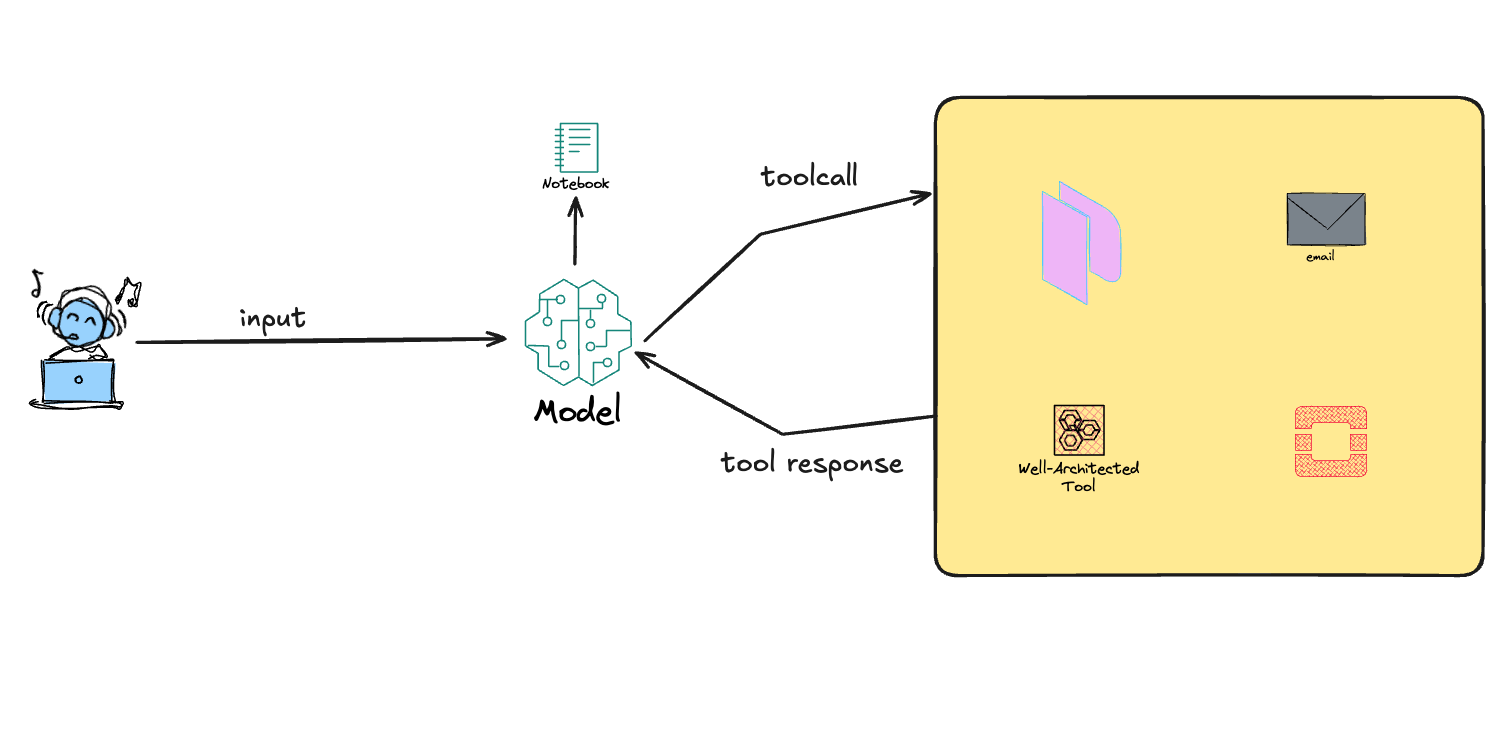

In [3]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [4]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o-mini")

llm.invoke("hi").content

'Hello! How can I assist you today?'

In [5]:
from langchain_community.tools import  DuckDuckGoSearchRun
from langchain.tools import tool

@tool
def search_duckduckgo(query: str) -> str:

    """This tool searches the latest news on DuckDuckGo for the given query and returns the results."""
    duck_search = DuckDuckGoSearchRun()
    return duck_search.invoke(query)



from langchain_community.tools import ArxivQueryRun
from langchain_community.utilities import ArxivAPIWrapper

@tool
def arxiv_tool(query: str) -> str:

    """"This tool allows you to query the arXiv database for research papers."""
    arxiv_query = ArxivQueryRun(api_wrapper=ArxivAPIWrapper())
    return arxiv_query.invoke(query)


from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

@tool
def wiki_tool(query: str):

    """This tool allows you to search Wikipedia for information on a given topic."""
    wiki_query = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
    return wiki_query.invoke(query)


@tool
def instagram(type: str):
    """ 
    use this tool to search profile and say weather its private or public
    """

    info = {
        "lock":"it is private account",
        "withoutlock":"its public account",
    }

    return info.get(type,"provided username has no id in instagram")

/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_44954/583735185.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import  DuckDuckGoSearchRun


In [6]:
tools = [instagram,wiki_tool,arxiv_tool,search_duckduckgo]

In [7]:
llm_with_tools = llm.bind_tools(tools)

In [8]:
llm_with_tools.invoke("manoj insta account doesnt have lock").tool_calls

[{'name': 'instagram',
  'args': {'type': 'manoj'},
  'id': 'call_AKzeEEkuYMuf9oRSth8WeGiF',
  'type': 'tool_call'}]

# **Langgraph Creation**

### **SChema creation**

In [11]:
from typing import TypedDict,List


class graph_scheama(TypedDict):
     messages:List
   

## **LLM Node Creation**

In [16]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
def llm_node(state: graph_scheama) -> graph_scheama:
    
    messages=state['messages']

    prompt = ChatPromptTemplate.from_messages(
        [
            ('system','you are helfull assitant answer all the question from tools'),
            ('human',"{input}")
        ]
    )


    llm = ChatOpenAI(model="gpt-4o-mini")

    chain = prompt | llm_with_tools 

    response = chain.invoke({"input":messages})

    state['messages'] = messages + [response]

    return state

## **Tool Node**

In [19]:
import stat

from langchain.messages import ToolMessage


def tool_node(state: graph_scheama) -> graph_scheama:
    messages=state['messages']

    tools_by_name = {tool.name: tool for tool in tools}

    tool_result = []

    for tool_call in messages[-1].tool_calls:
        tool = tools_by_name[tool_call["name"]]
        observation = tool.invoke(tool_call["args"])
        tool_result.append(ToolMessage(content=observation,tool_call_id=tool_call["id"]))

    state["messages"] = messages + tool_result

    return state



# Conditional EdgE

In [22]:
def if_tool_call(state: graph_scheama) -> graph_scheama:

    last_message = state['messages'][-1]

    if last_message.tool_calls:
        return "tool_node"
    else:
        return "end"


# GRAPH CREATION

In [24]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_scheama)

# Add nodes to the graph
graph.add_node("llm_node", llm_node)
graph.add_node("tool_node", tool_node)

# Add edges between nodes
graph.add_edge(START, "llm_node")
graph.add_conditional_edges("llm_node", if_tool_call,{"tool_node": "tool_node", "end": END})
graph.add_edge("tool_node", "llm_node")
graph.add_edge("llm_node", END)


react_graph = graph.compile()


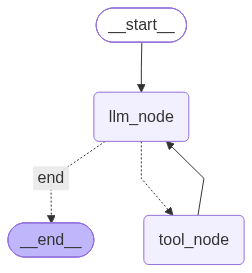

In [25]:
from IPython.display import Image, display

# You could see the errors with the below command
Image(react_graph.get_graph().draw_mermaid_png())

In [26]:
from langchain.messages import HumanMessage


react_graph.invoke({
    "messages":[HumanMessage(content="what is the lastest news about microsoft outlook")]
})

{'messages': [HumanMessage(content='what is the lastest news about microsoft outlook', additional_kwargs={}, response_metadata={}),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 21, 'prompt_tokens': 181, 'total_tokens': 202, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_05ca79a5f8', 'id': 'chatcmpl-Emd55lgLjVrual09xMtN46fUkPAei', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1fdc1-78fa-76a3-9276-1f4a5a21706c-0', tool_calls=[{'name': 'search_duckduckgo', 'args': {'query': 'latest news about Microsoft Outlook'}, 'id': 'call_NrQVYBNK2